# Preprocessing Comparison: Our Pipeline vs Plain Resizing

The Spanish baseline (model training notebook, section 6) lost about 5 macro-F1 points when applied to African images without any African training. To find out how much of this robustness comes from the Phase 2 image pipeline, this notebook trains the same model a second time on images that are only resized, and compares the two on the same African images.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
from statsmodels.stats.contingency_tables import mcnemar

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
MODELS = ROOT / "models"

from src.training import build_model, fit, get_device, load_model, make_loader, predict

random_seed = 42
np.random.seed(random_seed)

PLANES = ["Fetal abdomen", "Fetal brain", "Fetal femur", "Fetal thorax"]
SHORT_NAMES = [plane.replace("Fetal ", "") for plane in PLANES]
device = get_device()
print("Device:", device)

Device: mps


## 1. Design

The two models differ in one thing only: how each image is prepared before it reaches the network.

| | Our pipeline | Plain resizing |
|---|---|---|
| Image preparation | Fan mask, crop to the fan, trim extreme pixels, pad to a square, resize to 224 × 224 | Resize the whole image to 224 × 224 |
| Network | ResNet18 pretrained on ImageNet | Same |
| Training images | 5,220 Spanish training images | Same images |
| Augmentation | Phase 2 augmentation, training images only | Same |
| Class weights, optimiser, epochs, early stopping, seed | Model training notebook, section 3 | Same |
| Scaling for the network | ÷255, three channels, ImageNet constants | Same |

Plain resizing keeps everything in the original frame, including the black background, text, logos and the scanner's on-screen layout, and stretches the image to a square. The model trained with our pipeline is the saved Spanish baseline (`models/spanish_baseline.pt`); only the plain-resizing model is trained here.

Both models are evaluated on the 321 African development images **without any African training**, which is the comparison in question. The African test images are not used.

## 2. Loading the data

In [2]:
fetal_clean = pd.read_csv(PROCESSED / "fetal_clean.csv")
african_clean = pd.read_csv(PROCESSED / "african_clean.csv")

training = fetal_clean[fetal_clean["partition"] == "training"]
validation = fetal_clean[fetal_clean["partition"] == "validation"]
development = african_clean[african_clean["partition"] == "development"]

print("Spanish training:", len(training), "| Spanish validation:", len(validation),
      "| African development:", len(development))

Spanish training: 5220 | Spanish validation: 839 | African development: 321


## 3. Plain-resized images

Each image is converted to grayscale and resized to 224 × 224, with nothing else changed.

In [3]:
def fetal_path(row):
    return DATA_DIR / "fetal_planes_db" / "Images" / (row["Image_name"] + ".png")


def african_path(row):
    return DATA_DIR / "african_planes" / row["Center"] / (row["Filename"] + ".png")


def plain_resize(path, size=224):
    with Image.open(path) as image:
        return np.asarray(image.convert("L").resize((size, size), Image.BILINEAR))


plain_file = PROCESSED / "plain_resized.npz"
if plain_file.exists():
    saved = np.load(plain_file)
    fetal_plain, african_plain = saved["fetal"], saved["african"]
else:
    fetal_plain = np.stack([plain_resize(fetal_path(row)) for _, row in fetal_clean.iterrows()])
    african_plain = np.stack([plain_resize(african_path(row)) for _, row in african_clean.iterrows()])
    np.savez_compressed(plain_file, fetal=fetal_plain, african=african_plain)

fetal_ours = np.load(PROCESSED / "fetal_processed.npz")["images"]
african_ours = np.load(PROCESSED / "african_processed.npz")["images"]
print("Plain:", fetal_plain.shape, african_plain.shape, "| Ours:", fetal_ours.shape, african_ours.shape)

Plain: (6059, 224, 224) (396, 224, 224) | Ours: (6059, 224, 224) (396, 224, 224)


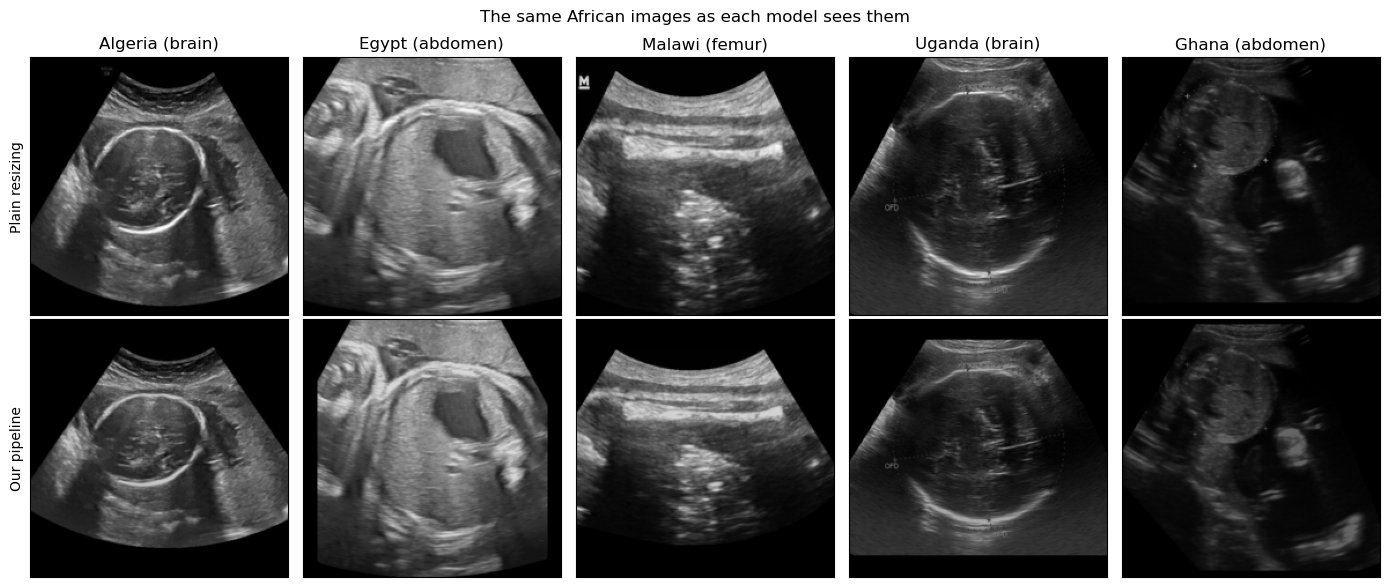

In [4]:
examples = development.groupby("Center").head(1)

fig, axes = plt.subplots(2, len(examples), figsize=(14, 6))
for c, (i, row) in enumerate(examples.iterrows()):
    axes[0, c].imshow(african_plain[i], cmap="gray", vmin=0, vmax=255)
    axes[1, c].imshow(african_ours[i], cmap="gray", vmin=0, vmax=255)
    axes[0, c].set_title(f"{row['Center']} ({row['Plane'].replace('Fetal ', '')})")
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel("Plain resizing")
axes[1, 0].set_ylabel("Our pipeline")
fig.suptitle("The same African images as each model sees them")
plt.tight_layout()
plt.savefig(FIGURES / "fig7_1_plain_vs_pipeline_examples.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Training the plain-resizing model

Same settings as the Spanish baseline: Adam (learning rate 0.0001, weight decay 0.0001), batch size 32, class-weighted cross-entropy, up to 10 epochs with early stopping on validation macro-F1 (patience 3), and the same seed.

In [5]:
weights = compute_class_weight("balanced", classes=np.arange(len(PLANES)), y=training["label"])
torch.manual_seed(random_seed)

train_loader = make_loader(fetal_plain[training.index], training["label"], train=True, seed=random_seed)
val_loader_plain = make_loader(fetal_plain[validation.index], validation["label"])

plain_model = build_model(num_classes=len(PLANES)).to(device)
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32).to(device))
optimizer = torch.optim.Adam(plain_model.parameters(), lr=1e-4, weight_decay=1e-4)

In [6]:
history = fit(plain_model, train_loader, val_loader_plain, loss_fn, optimizer, device, epochs=10, patience=3)
torch.save(plain_model.state_dict(), MODELS / "spanish_plain_resize.pt")
pd.DataFrame(history).set_index("epoch").round(3)

Epoch 1: loss 0.179 | validation accuracy 0.990 | macro-F1 0.987
Epoch 2: loss 0.043 | validation accuracy 0.993 | macro-F1 0.989
Epoch 3: loss 0.030 | validation accuracy 0.990 | macro-F1 0.987
Epoch 4: loss 0.022 | validation accuracy 0.993 | macro-F1 0.991
Epoch 5: loss 0.033 | validation accuracy 0.993 | macro-F1 0.991
Epoch 6: loss 0.014 | validation accuracy 0.995 | macro-F1 0.994
Epoch 7: loss 0.031 | validation accuracy 0.994 | macro-F1 0.991
Epoch 8: loss 0.015 | validation accuracy 0.994 | macro-F1 0.991
Epoch 9: loss 0.011 | validation accuracy 0.989 | macro-F1 0.985
Stopped early: no improvement for 3 epochs.


,train loss,validation accuracy,validation macro-F1
epoch,,,
1,0.179,0.990,0.987
2,0.043,0.993,0.989
3,0.030,0.990,0.987
4,0.022,0.993,0.991
5,0.033,0.993,0.991
6,0.014,0.995,0.994
7,0.031,0.994,0.991
8,0.015,0.994,0.991
9,0.011,0.989,0.985


In [7]:
# Optional: load the saved plain-resizing model instead of retraining it.
# plain_model = load_model(MODELS / "spanish_plain_resize.pt", device)

## 5. Predictions from both models

In [8]:
our_model = load_model(MODELS / "spanish_baseline.pt", device)

val_labels = validation["label"].to_numpy()
dev_labels = development["label"].to_numpy()

_, val_pred_ours, val_prob_ours = predict(our_model, make_loader(fetal_ours[validation.index], val_labels), device)
_, val_pred_plain, val_prob_plain = predict(plain_model, val_loader_plain, device)
_, dev_pred_ours, dev_prob_ours = predict(our_model, make_loader(african_ours[development.index], dev_labels), device)
_, dev_pred_plain, dev_prob_plain = predict(plain_model, make_loader(african_plain[development.index], dev_labels), device)

## 6. Results

Three measures are reported. **Accuracy** is the share of images classified correctly. **Macro-F1** averages the F1 score of each plane, so every plane counts equally. **AUC** (one plane against the rest, averaged over planes) measures how well the model ranks the correct plane above the others, regardless of the final decision. For countries without thorax images, macro-F1 and AUC are averaged over the planes that are present.

In [9]:
def scores(true, pred, prob):
    present = np.unique(true)
    auc = np.mean([roc_auc_score(true == k, prob[:, k]) for k in present])
    return {"accuracy": (pred == true).mean(),
            "macro-F1": f1_score(true, pred, average="macro", labels=present),
            "AUC": auc}


pd.DataFrame({
    ("Spanish validation", "Our pipeline"): scores(val_labels, val_pred_ours, val_prob_ours),
    ("Spanish validation", "Plain resizing"): scores(val_labels, val_pred_plain, val_prob_plain),
    ("African development", "Our pipeline"): scores(dev_labels, dev_pred_ours, dev_prob_ours),
    ("African development", "Plain resizing"): scores(dev_labels, dev_pred_plain, dev_prob_plain),
}).T.round(3)

accuracy  macro-F1    AUC
Spanish validation  Our pipeline       0.996     0.996  0.999
                    Plain resizing     0.995     0.994  1.000
African development Our pipeline       0.953     0.948  0.997
                    Plain resizing     0.922     0.904  0.994

### 6.1 Is the difference larger than chance?

Both models classified the same African images, so they can be compared image by image. McNemar's test uses only the images where the two models disagree: if the preprocessing made no difference, each model should be right on about half of them.

In [10]:
ours_correct = dev_pred_ours == dev_labels
plain_correct = dev_pred_plain == dev_labels

table = [[(ours_correct & plain_correct).sum(), (ours_correct & ~plain_correct).sum()],
         [(~ours_correct & plain_correct).sum(), (~ours_correct & ~plain_correct).sum()]]
print("Correct with our pipeline only:", table[0][1])
print("Correct with plain resizing only:", table[1][0])
print(f"McNemar exact p-value: {mcnemar(table, exact=True).pvalue:.4f}")

Correct with our pipeline only: 17
Correct with plain resizing only: 7
McNemar exact p-value: 0.0639


### 6.2 By country and by plane

In [11]:
by_country = pd.concat({
    name: pd.DataFrame({country: scores(dev_labels[development["Center"].to_numpy() == country],
                                        pred[development["Center"].to_numpy() == country],
                                        prob[development["Center"].to_numpy() == country])
                        for country in sorted(development["Center"].unique())}).T
    for name, (pred, prob) in {"Our pipeline": (dev_pred_ours, dev_prob_ours),
                               "Plain resizing": (dev_pred_plain, dev_prob_plain)}.items()
}, axis=1)
by_country.round(3)

Our pipeline                 Plain resizing                
            accuracy macro-F1    AUC       accuracy macro-F1    AUC
Algeria        0.983    0.983  1.000          0.900    0.900  0.997
Egypt          0.948    0.948  0.998          0.857    0.851  0.995
Ghana          0.912    0.929  0.992          0.930    0.946  0.993
Malawi         0.955    0.955  1.000          0.955    0.954  1.000
Uganda         0.967    0.974  1.000          0.983    0.983  1.000

In [12]:
by_plane = pd.DataFrame({
    "Our pipeline": [(dev_pred_ours[dev_labels == k] == k).mean() for k in range(len(PLANES))],
    "Plain resizing": [(dev_pred_plain[dev_labels == k] == k).mean() for k in range(len(PLANES))],
}, index=PLANES)
by_plane.round(3)

,Our pipeline,Plain resizing
Fetal abdomen,0.922,0.978
Fetal brain,1.000,0.967
Fetal femur,0.978,0.978
Fetal thorax,0.885,0.654


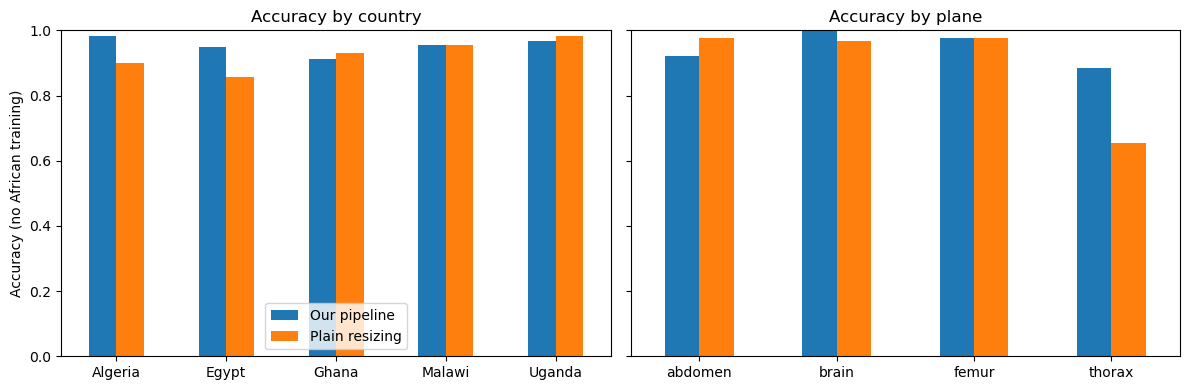

In [13]:
country_accuracy = by_country.xs("accuracy", axis=1, level=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
country_accuracy.plot.bar(ax=axes[0], rot=0)
by_plane.rename(index=lambda name: name.replace("Fetal ", "")).plot.bar(ax=axes[1], rot=0, legend=False)
axes[0].set_title("Accuracy by country")
axes[1].set_title("Accuracy by plane")
axes[0].set_ylabel("Accuracy (no African training)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylim(0, 1.0)
plt.tight_layout()
plt.savefig(FIGURES / "fig7_2_plain_vs_pipeline_by_country_plane.png", dpi=300, bbox_inches="tight")
plt.show()

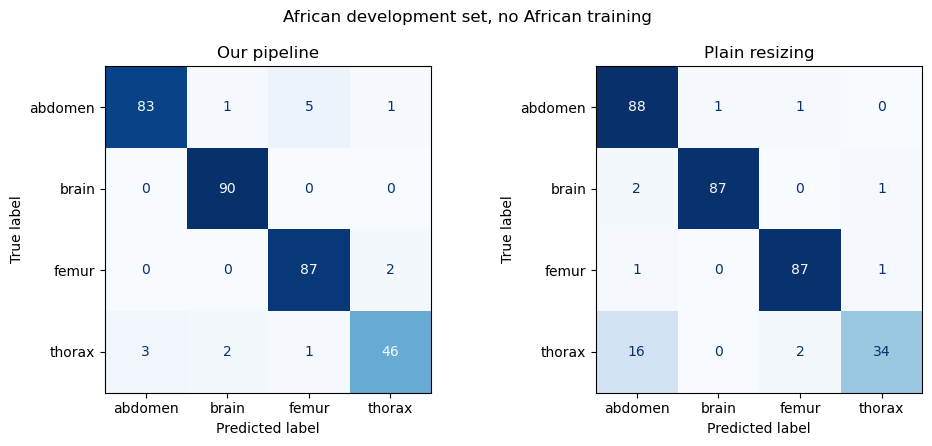

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, pred, title in [(axes[0], dev_pred_ours, "Our pipeline"), (axes[1], dev_pred_plain, "Plain resizing")]:
    ConfusionMatrixDisplay.from_predictions(dev_labels, pred, labels=range(len(PLANES)), display_labels=SHORT_NAMES,
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title)
fig.suptitle("African development set, no African training")
plt.tight_layout()
plt.savefig(FIGURES / "fig7_3_plain_vs_pipeline_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Summary

| African development set, no African training | Accuracy | Macro-F1 | AUC |
|---|---|---|---|
| Our pipeline | 0.953 | 0.948 | 0.997 |
| Plain resizing | 0.922 | 0.904 | 0.994 |

**On Spanish images the two models are the same.** Both reached about 99.5% accuracy on the Spanish validation set, so plain resizing is not a weaker model in general.

**On African images our pipeline is ahead by about 3 accuracy points and 4 macro-F1 points.** Our pipeline was right on 17 images that plain resizing got wrong, and plain resizing was right on 7 that our pipeline got wrong. McNemar's test gives p = 0.064, so with 321 images and a single training run the difference is suggestive but not statistically significant at the 5% level.

**The difference comes almost entirely from thorax.** Plain resizing classified 34 of 52 thorax images correctly (65%), against 46 of 52 (88%) for our pipeline; 16 of its thorax errors were predicted as abdomen. On the other planes the two models were similar, and plain resizing was slightly better on abdomen (97.8% against 92.2%).

**By country, the pattern follows thorax.** Our pipeline was better in Algeria (98.3% against 90.0%) and Egypt (94.8% against 85.7%), which both have thorax images. The two were equal in Malawi (95.5%), and plain resizing was slightly better in Ghana and Uganda, which have no thorax images.

**AUC hardly separates the two models** (0.997 against 0.994), even though accuracy differs by 3 points and thorax recall by 23 points. Both models rank the planes well, but plain resizing more often places a thorax image's highest score on abdomen.

**Plain resizing did not cause a collapse.** Even without our pipeline, the Spanish model classified 92.2% of African images correctly, and 95.5% of Malawi images. A large drop on African images is therefore not explained by the lack of masking and cropping alone.

**Limitations.** Each model was trained once with one seed, so part of the difference could come from training randomness. Only image preparation was compared; both models used the same augmentation.
